# How to locate a buggy sub with subwise profiling

## Why use subwise profiling

When a large FTQC circuit uses more T gates, more ancillas, or more Toffolis than you expected, the aggregate count from `GateCountEvaluatorHooks` tells you *that* something is off but not *where*. The usual workaround is to chop the circuit into pieces by hand, compile each piece, and count each piece in isolation until the offending sub shows up.

Subwise profiling removes that detour: it walks the compiled `MachineSub` once and reports, per `Sub`, its call count, qubit usage, and primitive-gate breakdown. The sub whose numbers do not match your expectation is the sub to inspect.

## Build a parametric circuit with nested subs

Suppose you are writing `ToffoliLadder(n)` by hand: a chain of Toffolis onto one shared target, one for each adjacent pair of the `n` controls. You expect the Toffoli count to grow **linearly** in `n` — one Toffoli per added control.

We will build it recursively: each level lays down one Toffoli and recurses on the remaining controls. The **intended** body has one recursive call per level. The **buggy** body has a copy-paste that recurses twice.


In [ ]:
from collections.abc import Sequence

from quri_parts.qsub.opsub import ParamUnitarySubDef, param_opsub
from quri_parts.qsub.register import QRegSpec
from quri_parts.qsub.sub import SubBuilder
from quri_parts.qsub.lib import std


# Someone defined ToffoliLadder by hand, but incorrect
class _ToffoliLadder(ParamUnitarySubDef[int]):
    name = "ToffoliLadder"

    def qubit_count_fn(self, n: int) -> int:
        return n + 1

    def qregs_fn(self, n: int) -> Sequence[QRegSpec]:
        return (QRegSpec("ctrl", n), QRegSpec("tgt", 1))

    def sub(self, b: SubBuilder, n: int) -> None:
        ctrls = b.qregs["ctrl"].qubits
        (tgt,) = b.qregs["tgt"].qubits
        if n == 1:
            b.add_op(std.CNOT, (ctrls[0], tgt))
            return
        if n == 2:
            b.add_op(std.Toffoli, (ctrls[0], ctrls[1], tgt))
            return
        # Bug: recursive call pasted twice -> Toffoli(n) = 2*Toffoli(n-1) + 1.
        b.add_op(ToffoliLadder(n - 1), (*ctrls[:-1], tgt))
        b.add_op(std.Toffoli, (ctrls[-2], ctrls[-1], tgt))
        b.add_op(ToffoliLadder(n - 1), (*ctrls[:-1], tgt))


ToffoliLadder, _ = param_opsub(_ToffoliLadder)


## Step 1. First approach: analysis with aggregate counting

Sweep `n` and run the existing `GateCountEvaluatorHooks`. The Toffoli count should grow by one per added control. Instead it doubles.


In [ ]:
from quri_parts.qsub.compile import compile
from quri_parts.qsub.evaluate import Evaluator
from quri_parts.qsub.eval import GateCountEvaluatorHooks

primitives = (
    std.X, std.H, std.T, std.Tdag, std.S, std.Sdag,
    std.CNOT, std.Toffoli,
)

for n in range(2, 8):
    compiled = compile(ToffoliLadder(n), primitives)
    totals = Evaluator(GateCountEvaluatorHooks((std.Toffoli,))).run(compiled)
    print(f"n={n}  ->", {k[1]: v for k, v in totals.items()})

n=2  -> {'Toffoli': 1}
n=3  -> {'Toffoli': 3}
n=4  -> {'Toffoli': 7}
n=5  -> {'Toffoli': 15}
n=6  -> {'Toffoli': 31}
n=7  -> {'Toffoli': 63}


Expected: `Toffoli = 1, 2, 3, 4, 5, 6`. Observed: `1, 3, 7, 15, 31, 63` — that is `2^{n-1} - 1`. Aggregate alone cannot say which level is doubling.

## Step 2. Second approach with subwise profiling

`SubwiseProfileEvaluatorHooks` is the new hook. Its API mirrors `GateCountEvaluatorHooks` so it slots into the same `Evaluator` pipeline:

- Constructor takes the gates you want broken down. Pass nothing to count *every* primitive that appears.
- `run(compiled)` returns a list of entries, one per distinct sub, parameters included — `ToffoliLadder(5)` and `ToffoliLadder(6)` get separate entries.
- Each entry exposes:
  - `source_op` — the `Ident` of the op this sub implements. Being the identifier rather than a formatted string, it compares directly against an op you already hold (`entry.source_op == ToffoliLadder(5).id`) and carries the parameters in `.params`. `to_str(full=False)` renders it in the usual qsub form, parameters in angle brackets: `ToffoliLadder<5>`. It is `None` for the entry sub of `compile_sub`, which is handed a `Sub` and so has no op.
  - `call_count` — how many times this sub is invoked across the program.
  - `qubit_counts` — the qubits the caller passes in (`data`), peak ancilla usage (`auxiliary`: the sub's own ancillas plus the largest among the subs it calls, since sequential callees reuse the same ancilla space), and their sum (`total`).
  - `gate_counts` — primitive-gate breakdown, one `GateCounts` per scope. Counts are keyed by the gate's `Ident`, so you look a gate up as `counts[std.Toffoli.id]`. Op parameters are part of that key, so `RZ(0.1)` and `RZ(0.2)` are counted apart — finer than `GateCountEvaluatorHooks`, which keys by `BaseIdent` and merges them. The `gates=` filter still selects by kind, so `gates=(std.RZ,)` keeps every angle. Each `GateCounts` holds `per_call` (a single invocation) and `all_calls` (multiplied by `call_count`):

| Scope | Attribute |
|---|---|
| Gates in this sub's own instructions | `own` |
| Gates contributed by every sub this one calls into, summed transitively | `descendants` |
| Sum of the two rows above | `cumulative` |

Put one row per entry into a dataframe, reading each scope at `std.Toffoli.id` (`desc` abbreviates `descendants`, `cum` `cumulative`):

In [ ]:
from collections.abc import Mapping

import pandas as pd

from quri_parts.qsub.eval import SubwiseProfileEntry, SubwiseProfileEvaluatorHooks
from quri_parts.qsub.op import Ident

compiled = compile(ToffoliLadder(6), primitives)
report_data = Evaluator(SubwiseProfileEvaluatorHooks(gates=(std.Toffoli,))).run(compiled)

TOFFOLI = std.Toffoli.id


def sub_ident_name(ident: Ident | None) -> str:
    return ident.to_str(full=False) if ident else "<entry>"


def sub_name(entry: SubwiseProfileEntry) -> str:
    return sub_ident_name(entry.source_op)


def by_gate_name(counts: Mapping[Ident, int]) -> dict[str, int]:
    return {ident.to_str(full=False): n for ident, n in counts.items()}


def profile_table(report: Sequence[SubwiseProfileEntry]) -> pd.DataFrame:
    return pd.DataFrame([
        {
            "sub": sub_name(e),
            "call_count": e.call_count,
            "qubits": e.qubit_counts.total,
            "Toffoli own/call": e.gate_counts.own.per_call.get(TOFFOLI, 0),
            "Toffoli desc/call": e.gate_counts.descendants.per_call.get(TOFFOLI, 0),
            "Toffoli cum/call": e.gate_counts.cumulative.per_call.get(TOFFOLI, 0),
            "Toffoli cum total": e.gate_counts.cumulative.all_calls.get(TOFFOLI, 0),
        }
        for e in report
    ])


profile_table(report_data)

,sub,call_count,qubits,Toffoli own/call,Toffoli desc/call,Toffoli cum/call,Toffoli cum total
0,ToffoliLadder<6>,1,7,1,30,31,31
1,ToffoliLadder<5>,2,6,1,14,15,30
2,ToffoliLadder<4>,4,5,1,6,7,28
3,ToffoliLadder<3>,8,4,1,2,3,24
4,ToffoliLadder<2>,16,3,1,0,1,16


Two things jump out from the table above:

1. `Toffoli own/call` is `1` at every level. No single body inlines 'too many' Toffolis.
2. `call_count` doubles per level (`1, 2, 4, 8, 16`) and `Toffoli desc/call` grows by roughly 2x per level (`30, 14, 6, 2, 0`). The blow-up lives in the **child fan-out**, not in any one body.


## Step 3. Draw the call graph

The table says the blow-up lives in the child fan-out. `CallGraphEvaluatorHooks` extracts that structure: evaluating the same compiled sub returns the call graph as a dict, mapping each sub to the distinct subs it calls directly (leaves map to an empty list). Nodes are op `Ident`s — the same identity the profile reports as `source_op` — so the two reports join on them.

In [ ]:
from quri_parts.qsub.eval import CallGraphEvaluatorHooks

call_graph = Evaluator(CallGraphEvaluatorHooks()).run(compiled)

{
    sub_ident_name(caller): [sub_ident_name(c) for c in callees]
    for caller, callees in call_graph.items()
}

{'ToffoliLadder<6>': ['ToffoliLadder<5>'],
 'ToffoliLadder<5>': ['ToffoliLadder<4>'],
 'ToffoliLadder<4>': ['ToffoliLadder<3>'],
 'ToffoliLadder<3>': ['ToffoliLadder<2>'],
 'ToffoliLadder<2>': []}

The shape alone looks innocent — a plain chain, and (since repeated calls of the same sub are recorded once) *identical* to what the fixed version will produce. The signal appears when each node is annotated with its profile entry and each edge with its call multiplicity. Every sub here has a single caller, so the ratio of child to parent `call_count` is the number of calls per parent invocation.

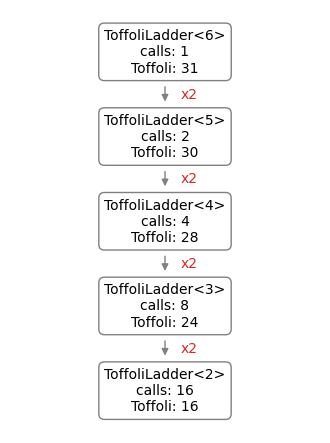

In [ ]:
import matplotlib.pyplot as plt


def plot_call_graph(
    graph: dict[Ident | None, list[Ident]], report: Sequence[SubwiseProfileEntry]
) -> None:
    entries = {e.source_op: e for e in report}

    # Layer each node by its longest path from the root.
    depth: dict[Ident | None, int] = {}
    called = {callee for callees in graph.values() for callee in callees}

    def assign(ident: Ident | None, d: int) -> None:
        depth[ident] = max(d, depth.get(ident, 0))
        for callee in graph[ident]:
            assign(callee, d + 1)

    for root in (n for n in graph if n not in called):
        assign(root, 0)

    layers: dict[int, list[Ident | None]] = {}
    for ident, d in depth.items():
        layers.setdefault(d, []).append(ident)
    pos = {}
    for d, idents in layers.items():
        for i, ident in enumerate(sorted(idents, key=str)):
            pos[ident] = (i - (len(idents) - 1) / 2, -d)

    _, ax = plt.subplots(figsize=(4, 1.1 * len(layers)))
    for ident, (x, y) in pos.items():
        e = entries[ident]
        toffoli = e.gate_counts.cumulative.all_calls.get(TOFFOLI, 0)
        label = f"{sub_name(e)}\ncalls: {e.call_count}\nToffoli: {toffoli}"
        ax.text(x, y, label, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray"))
    for caller, callees in graph.items():
        for callee in callees:
            (x0, y0), (x1, y1) = pos[caller], pos[callee]
            ax.annotate("", xy=(x1, y1 + 0.38), xytext=(x0, y0 - 0.38),
                        arrowprops=dict(arrowstyle="-|>", color="gray"))
            # Calls per parent invocation; valid while each sub has one caller.
            m = entries[callee].call_count // entries[caller].call_count
            ax.text((x0 + x1) / 2 + 0.1, (y0 + y1) / 2, f"x{m}",
                    ha="left", va="center", color="tab:red" if m > 1 else "gray")
    ax.set_xlim(min(x for x, _ in pos.values()) - 1, max(x for x, _ in pos.values()) + 1)
    ax.set_ylim(-max(layers) - 0.5, 0.5)
    ax.axis("off")
    plt.show()


plot_call_graph(call_graph, report_data)

Every edge is x2 where the intended decomposition has x1 — no single level is at fault; the doubling compounds. Following the (single) path from the root shows the multiplication accumulating into each level's `call_count`:

In [ ]:
entries = {e.source_op: e for e in report_data}

ident = ToffoliLadder(6).id
path = []
while True:
    path.append(f"{ident.to_str(full=False)} x{entries[ident].call_count}")
    callees = call_graph[ident]
    if not callees:
        break
    ident = callees[0]
print("  ->  ".join(path))

ToffoliLadder<6> x1  ->  ToffoliLadder<5> x2  ->  ToffoliLadder<4> x4  ->  ToffoliLadder<3> x8  ->  ToffoliLadder<2> x16


## Step 4. Zoom in on the offending sub

Pick a single entry out of the report and inspect it on its own. Because `source_op` is an identifier, we match it against the op we are after.

In [ ]:
mcx5_entry = next(e for e in report_data if e.source_op == ToffoliLadder(5).id)
print("sub:", sub_name(mcx5_entry))
print("params:", mcx5_entry.source_op.params)
print("calls:", mcx5_entry.call_count)
print("qubits:", mcx5_entry.qubit_counts)
print("own (per call):", by_gate_name(mcx5_entry.gate_counts.own.per_call))
print("descendants (per call):", by_gate_name(mcx5_entry.gate_counts.descendants.per_call))
print("cumulative (per call):", by_gate_name(mcx5_entry.gate_counts.cumulative.per_call))

sub: ToffoliLadder<5>
params: (5,)
calls: 2
qubits: QubitCounts(data=6, auxiliary=0, total=6)
own (per call): {'Toffoli': 1}
descendants (per call): {'Toffoli': 14}
cumulative (per call): {'Toffoli': 15}


`ToffoliLadder<5>`: `own.per_call = {Toffoli: 1}`, `cumulative.per_call = 15`. The gap is below it, not in this body.

## Step 5. Fix and re-check

Delete the duplicate recursive call from `_ToffoliLadder.sub`, redefine the sub, and sweep `n` again. The Toffoli count should now grow by one per added control.


In [ ]:
class _ToffoliLadder(ParamUnitarySubDef[int]):  # noqa: F811 — replacing the buggy definition
    name = "ToffoliLadder"

    def qubit_count_fn(self, n: int) -> int:
        return n + 1

    def qregs_fn(self, n: int) -> Sequence[QRegSpec]:
        return (QRegSpec("ctrl", n), QRegSpec("tgt", 1))

    def sub(self, b: SubBuilder, n: int) -> None:
        ctrls = b.qregs["ctrl"].qubits
        (tgt,) = b.qregs["tgt"].qubits
        if n == 1:
            b.add_op(std.CNOT, (ctrls[0], tgt))
            return
        if n == 2:
            b.add_op(std.Toffoli, (ctrls[0], ctrls[1], tgt))
            return
        b.add_op(ToffoliLadder(n - 1), (*ctrls[:-1], tgt))
        b.add_op(std.Toffoli, (ctrls[-2], ctrls[-1], tgt))


ToffoliLadder, _ = param_opsub(_ToffoliLadder)

for n in range(2, 8):
    compiled = compile(ToffoliLadder(n), primitives)
    totals = Evaluator(GateCountEvaluatorHooks((std.Toffoli,))).run(compiled)
    print(f"n={n}  ->", {k[1]: v for k, v in totals.items()})

n=2  -> {'Toffoli': 1}
n=3  -> {'Toffoli': 2}
n=4  -> {'Toffoli': 3}
n=5  -> {'Toffoli': 4}
n=6  -> {'Toffoli': 5}
n=7  -> {'Toffoli': 6}


Subwise profiling on the fixed version should now show `call_count = 1` for every level and `Toffoli desc/call` shrinking by one per level.

In [ ]:
compiled = compile(ToffoliLadder(6), primitives)
report_data_fixed = Evaluator(SubwiseProfileEvaluatorHooks(gates=(std.Toffoli,))).run(compiled)

profile_table(report_data_fixed)

,sub,call_count,qubits,Toffoli own/call,Toffoli desc/call,Toffoli cum/call,Toffoli cum total
0,ToffoliLadder<6>,1,7,1,4,5,5
1,ToffoliLadder<5>,1,6,1,3,4,4
2,ToffoliLadder<4>,1,5,1,2,3,3
3,ToffoliLadder<3>,1,4,1,1,2,2
4,ToffoliLadder<2>,1,3,1,0,1,1


The call graph confirms the fix from the structural side: the chain is unchanged, but every edge is x1 and the Toffoli totals now shrink by one per level.

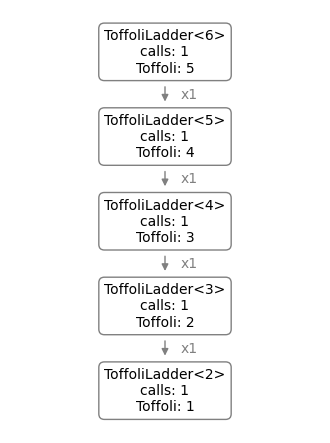

In [ ]:
call_graph_fixed = Evaluator(CallGraphEvaluatorHooks()).run(compiled)
plot_call_graph(call_graph_fixed, report_data_fixed)

In production, prefer an audited library sub where one exists; subwise profiling is for the cases where you have to roll your own.